# Сравнение алгоритмов из работ 1–5

Фокин Леонид Александрович, группа 401, вариант 20.

Wholesale Customers: 88 тестовых покупателей. SGEMM: 600 тестовых конфигураций. Внутри каждой задачи разбиение одинаково для всех работ. Сравниваю по macro-F1 и MAE; accuracy и RMSE нужны как дополнительные метрики. Все параметры выбирались на обучающей части, по пяти фолдам.

CSV содержат тестовые оценки из исходных ноутбуков; повторное обучение для просмотра итогов не нужно. Проверяю, что для каждого алгоритма и задачи есть четыре версии без повторов.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

names = {1: 'KNN', 2: 'Логистическая / линейная', 3: 'Дерево', 4: 'Лес', 5: 'Бустинг'}
order = ['sklearn baseline', 'sklearn improved', 'own baseline', 'own improved']
results = pd.concat([pd.read_csv(Path('results') / f'lab{i}.csv').assign(model=name)
                     for i, name in names.items()], ignore_index=True)
expected = pd.MultiIndex.from_product([names.values(), ['classification', 'regression'], order])
keys = results.set_index(['model', 'task', 'version']).index
assert len(keys) == len(expected) and keys.is_unique and expected.difference(keys).empty

Сортирую классификаторы по убыванию macro-F1, регрессоры по возрастанию MAE.

In [2]:
cls = results.query("task == 'classification'").sort_values('f1_macro', ascending=False)
reg = results.query("task == 'regression'").sort_values('mae_ms')
display(cls[['model', 'version', 'f1_macro', 'accuracy']].reset_index(drop=True).round(4))
display(reg[['model', 'version', 'mae_ms', 'rmse_ms']].reset_index(drop=True).round(2))

,model,version,f1_macro,accuracy
0,Бустинг,own baseline,0.9108,0.9205
1,Бустинг,sklearn improved,0.9108,0.9205
2,Бустинг,own improved,0.9108,0.9205
3,Бустинг,sklearn baseline,0.9108,0.9205
4,Лес,sklearn improved,0.9108,0.9205
5,Лес,own improved,0.9108,0.9205
6,Лес,sklearn baseline,0.9108,0.9205
7,Дерево,own improved,0.9004,0.9091
8,Дерево,sklearn improved,0.9004,0.9091
9,KNN,sklearn improved,0.8989,0.9091


,model,version,mae_ms,rmse_ms
0,Лес,sklearn improved,20.35,42.47
1,Лес,own improved,21.07,44.91
2,Дерево,own improved,23.89,55.98
3,Лес,sklearn baseline,24.65,48.65
4,Дерево,sklearn improved,24.68,57.78
5,Лес,own baseline,24.96,51.23
6,Дерево,own baseline,31.18,80.10
7,Дерево,sklearn baseline,32.06,84.04
8,Бустинг,own improved,33.21,66.20
9,Бустинг,sklearn improved,33.36,66.44


На графиках сопоставляю четыре версии. В таблицах отдельно показываю эффект настройки и разницу между реализациями с одинаковыми признаками и параметрами.

version,sklearn baseline,sklearn improved,own baseline,own improved,sklearn_delta,own_delta,own_vs_sklearn
model,,,,,,,
KNN,0.8620,0.8989,0.8620,0.8989,0.0368,0.0368,0.0
Логистическая,0.8832,0.8971,0.8832,0.8971,0.0139,0.0139,0.0
Дерево,0.8736,0.9004,0.8527,0.9004,0.0268,0.0477,0.0
Лес,0.9108,0.9108,0.8971,0.9108,0.0000,0.0136,0.0
Бустинг,0.9108,0.9108,0.9108,0.9108,0.0000,0.0000,0.0


version,sklearn baseline,sklearn improved,own baseline,own improved,sklearn_delta,own_delta,own_vs_sklearn
model,,,,,,,
KNN,88.9032,56.7358,89.0911,56.7358,-32.1674,-32.3552,0.0000
Линейная,178.7355,170.3948,178.7355,170.3948,-8.3407,-8.3407,-0.0000
Дерево,32.0561,24.6829,31.1828,23.8860,-7.3732,-7.2968,-0.7968
Лес,24.6465,20.3524,24.9637,21.0726,-4.2942,-3.8911,0.7203
Бустинг,86.3128,33.3555,86.3128,33.2128,-52.9573,-53.1000,-0.1427


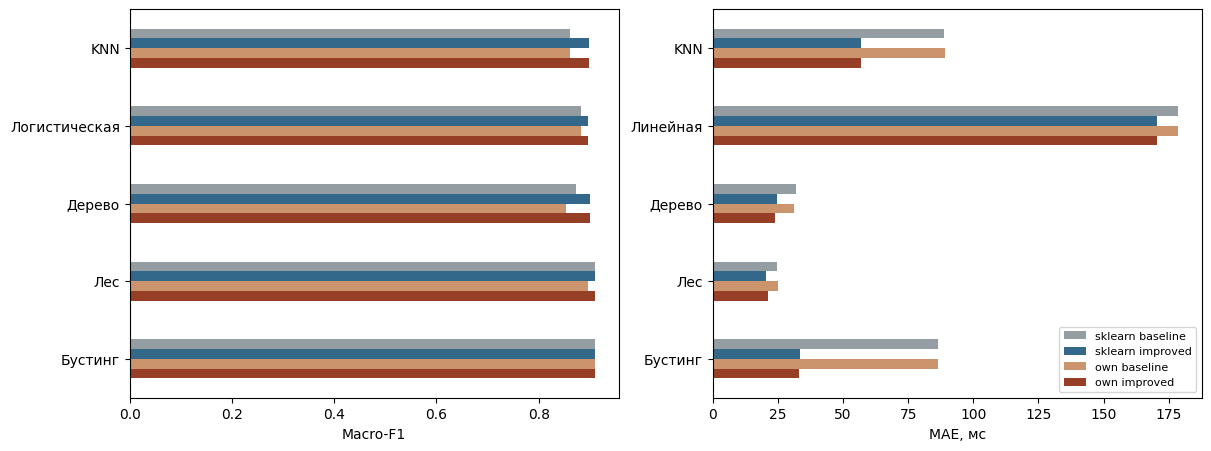

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout='constrained')
for ax, frame, metric, label in [(axes[0], cls, 'f1_macro', 'Macro-F1'),
                                  (axes[1], reg, 'mae_ms', 'MAE, мс')]:
    wide = frame.pivot(index='model', columns='version', values=metric).reindex(names.values())[order]
    wide = wide.rename(index={'Логистическая / линейная': 'Логистическая' if metric == 'f1_macro' else 'Линейная'})
    wide.plot.barh(ax=ax, color=['#939da2', '#34688b', '#cc946c', '#963f26'], legend=False)
    ax.set(xlabel=label, ylabel='')
    ax.invert_yaxis()
    display(wide.assign(sklearn_delta=wide['sklearn improved'] - wide['sklearn baseline'],
                        own_delta=wide['own improved'] - wide['own baseline'],
                        own_vs_sklearn=wide['own improved'] - wide['sklearn improved']).round(4))
axes[1].legend(loc='lower right', fontsize=8)
plt.show()

## Выводы

- **Wholesale Customers.** Лучший тестовый macro-F1, 0,9108 при accuracy 0,9205, разделили лес и бустинг. KNN, логистическая регрессия и дерево после подбора тоже выросли относительно собственных библиотечных бейзлайнов. Оставил бы лес sklearn с настройками по умолчанию: настройка леса и переход на бустинг не повысили тестовый macro-F1. При 88 покупателях рейтинг чувствителен к нескольким ошибкам, а одинаковые метрики не означают одинаковые прогнозы.
- **SGEMM.** Настроенный лес sklearn получил минимальные MAE 20,35 и RMSE 42,47 мс. Самописный лес с теми же признаками получил 21,07 и 44,91 мс. Одиночное дерево с новыми признаками достигло 24,68 мс (sklearn) и 23,89 мс (самописное) по MAE. Бустинг снизил MAE сильнее всего относительно собственного библиотечного бейзлайна, но не обошёл лес или дерево. Для прогноза на том же GPU выбрал бы настроенный лес; перенос на другое оборудование не проверялся.
- **Самописные модели.** С настройками sklearn варианты KNN и линейных моделей практически совпали с библиотечными. У деревьев и ансамблей есть небольшие расхождения из-за выбора разбиений и случайного отбора. Это результаты одного тестового разбиения. Чтобы проверить устойчивость рейтинга, нужен отдельный тест или повторная вложенная кросс-валидация.